# Heart Disease Prediction System

**Live App:** [https://heart-disease-fa24-bse-085.streamlit.app](https://heart-disease-fa24-bse-085.streamlit.app)

**GitHub Repo:** [https://github.com/VicegerentPrince/ml-lab-assignment-2](https://github.com/VicegerentPrince/ml-lab-assignment-2)

| | |
|:--|:--|
| **Student** | Muhammad Muneeb Shahzad |
| **Registration No.** | FA24-BSE-085 |
| **Course** | Machine Learning Fundamentals (AIC354) |
| **Instructor** | Dr. Rao Muhammad Adeel Nawab |
| **Assignment** | Assignment 2, Task 2 |

## Introduction
This system predicts if a patient has heart disease or not. It is a binary classification task. I changed the Titanic Passenger Survival Prediction code for the Heart Disease dataset and followed the same steps.

**Dataset:** [Heart Disease dataset from UCI](https://archive.ics.uci.edu/dataset/45/heart+disease). I used the file `processed.cleveland.data`. It has 303 patients and 14 attributes. Only 4 input attributes are used.

## Input and Output

### Inputs

| Input Attribute | Name in Dataset | Meaning | Possible Values |
|:--|:--|:--|:--|
| **ChestPain** | cp | Type of chest pain | Typical, Atypical, NonAnginal, Asymptomatic |
| **ExerciseAngina** | exang | Chest pain during exercise | Yes, No |
| **Vessels** | ca | Number of main blood vessels seen in the X-ray test | Zero, One, Two, Three |
| **Thal** | thal | Result of the thallium heart scan | Normal, Fixed, Reversible |

### Output

| Output Attribute | Name in Dataset | Possible Values |
|:--|:--|:--|
| **HeartDisease** | num | Yes, No |

## Code

### Step 1: Import Libraries

In [1]:
import numpy as np
import pandas as pd
import pickle

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn import svm
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

from prettytable import PrettyTable
import matplotlib.pyplot as plt
import seaborn as sns

### Step 2: Load Sample Data

In [2]:
# The file has no heading row, so the column names are written here
column_names = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
                "thalach", "exang", "oldpeak", "slope", "ca", "thal", "num"]

# Missing values are written as ? in the file
heart_data = pd.read_csv("processed.cleveland.data", names=column_names, na_values="?")

pd.set_option("display.max_rows", None, "display.max_columns", None, "display.width", 200)

print("\n\nHeart Disease Data (first 10 rows):")
print("===================================\n")
print(heart_data.head(10))



Heart Disease Data (first 10 rows):

    age  sex   cp  trestbps   chol  fbs  restecg  thalach  exang  oldpeak  slope   ca  thal  num
0  63.0  1.0  1.0     145.0  233.0  1.0      2.0    150.0    0.0      2.3    3.0  0.0   6.0    0
1  67.0  1.0  4.0     160.0  286.0  0.0      2.0    108.0    1.0      1.5    2.0  3.0   3.0    2
2  67.0  1.0  4.0     120.0  229.0  0.0      2.0    129.0    1.0      2.6    2.0  2.0   7.0    1
3  37.0  1.0  3.0     130.0  250.0  0.0      0.0    187.0    0.0      3.5    3.0  0.0   3.0    0
4  41.0  0.0  2.0     130.0  204.0  0.0      2.0    172.0    0.0      1.4    1.0  0.0   3.0    0
5  56.0  1.0  2.0     120.0  236.0  0.0      0.0    178.0    0.0      0.8    1.0  0.0   3.0    0
6  62.0  0.0  4.0     140.0  268.0  0.0      2.0    160.0    0.0      3.6    3.0  2.0   3.0    3
7  57.0  0.0  4.0     120.0  354.0  0.0      0.0    163.0    1.0      0.6    1.0  0.0   3.0    0
8  63.0  1.0  4.0     130.0  254.0  0.0      2.0    147.0    0.0      1.4    2.0  1.0   

### Step 3: Understand and Pre-process Sample Data

#### Step 3.1: Understand Sample Data

In [3]:
print("\n\nAttributes in Data:")
print("===================\n")
print(heart_data.columns)

print("\n\nNumber of Instances in Data:", heart_data["age"].count())
print("================================\n")

print("\n\nMissing Values in each Attribute:")
print("=================================\n")
print(heart_data.isnull().sum())

print("\n\nValues of the Output Attribute (num):")
print("=====================================\n")
print(heart_data["num"].value_counts())



Attributes in Data:

Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num'], dtype='object')


Number of Instances in Data: 303



Missing Values in each Attribute:

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
num         0
dtype: int64


Values of the Output Attribute (num):

num
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64


#### Step 3.2: Pre-process Sample Data
- Only 4 input attributes (cp, exang, ca, thal) and the output (num) are kept
- Rows with missing values are removed
- Number codes are changed to names, so the data can be label encoded like the Titanic data
- In the output, 0 means no heart disease and 1 to 4 mean heart disease, so it is changed to No and Yes

In [4]:
# Keep only the 4 input attributes and the output attribute
sample_data = heart_data[["cp", "exang", "ca", "thal", "num"]].copy()

# Remove the rows that have missing values
sample_data = sample_data.dropna()
sample_data = sample_data.reset_index(drop=True)

# Give easy names to the columns
sample_data.columns = ["ChestPain", "ExerciseAngina", "Vessels", "Thal", "HeartDisease"]

# Change the number codes to names
sample_data["ChestPain"] = sample_data["ChestPain"].replace({1: "Typical", 2: "Atypical", 3: "NonAnginal", 4: "Asymptomatic"})
sample_data["ExerciseAngina"] = sample_data["ExerciseAngina"].replace({0: "No", 1: "Yes"})
sample_data["Vessels"] = sample_data["Vessels"].replace({0: "Zero", 1: "One", 2: "Two", 3: "Three"})
sample_data["Thal"] = sample_data["Thal"].replace({3: "Normal", 6: "Fixed", 7: "Reversible"})
sample_data["HeartDisease"] = sample_data["HeartDisease"].replace({0: "No", 1: "Yes", 2: "Yes", 3: "Yes", 4: "Yes"})

# Save the pre-processed data
sample_data.to_csv("sample-data.csv", index=False, header=True)

print("\n\nSample Data after Pre-processing (first 10 rows):")
print("=================================================\n")
print(sample_data.head(10))

print("\n\nNumber of Instances in Sample Data:", sample_data["ChestPain"].count())
print("=======================================\n")



Sample Data after Pre-processing (first 10 rows):

      ChestPain ExerciseAngina Vessels        Thal HeartDisease
0       Typical             No    Zero       Fixed           No
1  Asymptomatic            Yes   Three      Normal          Yes
2  Asymptomatic            Yes     Two  Reversible          Yes
3    NonAnginal             No    Zero      Normal           No
4      Atypical             No    Zero      Normal           No
5      Atypical             No    Zero      Normal           No
6  Asymptomatic             No     Two      Normal          Yes
7  Asymptomatic            Yes    Zero      Normal           No
8  Asymptomatic             No     One  Reversible          Yes
9  Asymptomatic            Yes    Zero  Reversible          Yes


Number of Instances in Sample Data: 297



### Step 4: Feature Extraction
- The 4 input attributes were selected in Step 3.2
- No Feature Extraction needs to be performed
- The tables below show how many patients have heart disease for each value

In [5]:
print(pd.crosstab(sample_data["ChestPain"], sample_data["HeartDisease"]), "\n")
print(pd.crosstab(sample_data["ExerciseAngina"], sample_data["HeartDisease"]), "\n")
print(pd.crosstab(sample_data["Vessels"], sample_data["HeartDisease"]), "\n")
print(pd.crosstab(sample_data["Thal"], sample_data["HeartDisease"]))

HeartDisease  No  Yes
ChestPain            
Asymptomatic  39  103
Atypical      40    9
NonAnginal    65   18
Typical       16    7 

HeartDisease     No  Yes
ExerciseAngina          
No              137   63
Yes              23   74 

HeartDisease   No  Yes
Vessels               
One            21   44
Three           3   17
Two             7   31
Zero          129   45 

HeartDisease   No  Yes
Thal                  
Fixed           6   12
Normal        127   37
Reversible     27   88


### Step 5: Label Encoding the Sample Data (Input and Output is converted in Numeric Representation)

#### Step 5.1: Train the Label Encoder

In [6]:
# Possible values of each attribute
chest_pain = pd.DataFrame({"ChestPain": ["Typical", "Atypical", "NonAnginal", "Asymptomatic"]})
exercise_angina = pd.DataFrame({"ExerciseAngina": ["Yes", "No"]})
vessels = pd.DataFrame({"Vessels": ["Zero", "One", "Two", "Three"]})
thal = pd.DataFrame({"Thal": ["Normal", "Fixed", "Reversible"]})
heart_disease = pd.DataFrame({"HeartDisease": ["Yes", "No"]})

# One label encoder for each attribute
chest_pain_label_encoder = LabelEncoder()
exercise_angina_label_encoder = LabelEncoder()
vessels_label_encoder = LabelEncoder()
thal_label_encoder = LabelEncoder()
heart_disease_label_encoder = LabelEncoder()

# Train the label encoders
chest_pain_label_encoder.fit(np.ravel(chest_pain))
exercise_angina_label_encoder.fit(np.ravel(exercise_angina))
vessels_label_encoder.fit(np.ravel(vessels))
thal_label_encoder.fit(np.ravel(thal))
heart_disease_label_encoder.fit(np.ravel(heart_disease))

# The position of each value is its code (first value is 0, second is 1 and so on)
print("ChestPain:", chest_pain_label_encoder.classes_)
print("ExerciseAngina:", exercise_angina_label_encoder.classes_)
print("Vessels:", vessels_label_encoder.classes_)
print("Thal:", thal_label_encoder.classes_)
print("HeartDisease:", heart_disease_label_encoder.classes_)

ChestPain: ['Asymptomatic' 'Atypical' 'NonAnginal' 'Typical']
ExerciseAngina: ['No' 'Yes']
Vessels: ['One' 'Three' 'Two' 'Zero']
Thal: ['Fixed' 'Normal' 'Reversible']
HeartDisease: ['No' 'Yes']


#### Step 5.2: Label Encode the Output

In [7]:
sample_data_encoded = sample_data.copy()

# No becomes 0 and Yes becomes 1
sample_data_encoded["HeartDisease"] = heart_disease_label_encoder.transform(sample_data["HeartDisease"])

print("\n\nHeartDisease Attribute After Label Encoding (first 10 rows):")
print("============================================================\n")
print(pd.DataFrame({
    "HeartDisease": sample_data["HeartDisease"],
    "encoded_heart_disease": sample_data_encoded["HeartDisease"]
}).head(10))

sample_data_encoded.to_csv("sample-data-encoded-output.csv", index=False, header=True)
print("\nSaved: sample-data-encoded-output.csv")



HeartDisease Attribute After Label Encoding (first 10 rows):

  HeartDisease  encoded_heart_disease
0           No                      0
1          Yes                      1
2          Yes                      1
3           No                      0
4           No                      0
5           No                      0
6          Yes                      1
7           No                      0
8          Yes                      1
9          Yes                      1

Saved: sample-data-encoded-output.csv


#### Step 5.3: Label Encode the Input

In [8]:
sample_data_encoded["ChestPain"] = chest_pain_label_encoder.transform(sample_data["ChestPain"])
sample_data_encoded["ExerciseAngina"] = exercise_angina_label_encoder.transform(sample_data["ExerciseAngina"])
sample_data_encoded["Vessels"] = vessels_label_encoder.transform(sample_data["Vessels"])
sample_data_encoded["Thal"] = thal_label_encoder.transform(sample_data["Thal"])

print("\n\nSample Data after Label Encoding (first 10 rows):")
print("=================================================\n")
print(sample_data_encoded.head(10))

sample_data_encoded.to_csv("sample-data-encoded.csv", index=False, header=True)
print("\nSaved: sample-data-encoded.csv")



Sample Data after Label Encoding (first 10 rows):

   ChestPain  ExerciseAngina  Vessels  Thal  HeartDisease
0          3               0        3     0             0
1          0               1        1     1             1
2          0               1        2     2             1
3          2               0        3     1             0
4          1               0        3     1             0
5          1               0        3     1             0
6          0               0        2     1             1
7          0               1        3     1             0
8          0               0        0     2             1
9          0               1        3     2             1

Saved: sample-data-encoded.csv


### Step 6: Execute the Training Phase

#### Step 6.1: Splitting Sample Data into Training Data and Testing Data

In [9]:
# 80% of the data is for training and 20% is for testing
training_data_encoded, testing_data_encoded = train_test_split(
    sample_data_encoded,
    test_size=0.2,
    random_state=0,
    shuffle=False
)

training_data_encoded.to_csv("training-data-encoded.csv", index=False, header=True)
testing_data_encoded.to_csv("testing-data-encoded.csv", index=False, header=True)

print("Training Data shape:", training_data_encoded.shape)
print("Testing Data shape:", testing_data_encoded.shape)

Training Data shape: (237, 5)
Testing Data shape: (60, 5)


#### Step 6.2: Splitting Input Vectors and Outputs / Labels of Training Data

In [10]:
# The first 4 columns are the inputs and the last column is the output
input_vector_train = training_data_encoded.iloc[:, :-1]
output_label_train = training_data_encoded.iloc[:, -1]

print("Input vectors (train) shape:", input_vector_train.shape)
print("Output labels (train) shape:", output_label_train.shape)

Input vectors (train) shape: (237, 4)
Output labels (train) shape: (237,)


#### Step 6.3: Train the Support Vector Classifier

In [11]:
print("\n\nTraining the Support Vector Classifier on Training Data")
print("========================================================\n")

svc_model = svm.SVC(gamma="auto", random_state=0)
svc_model.fit(input_vector_train, np.ravel(output_label_train))

print(svc_model)



Training the Support Vector Classifier on Training Data

SVC(gamma='auto', random_state=0)


#### Step 6.4: Save the Trained Model

In [12]:
with open("svc_trained_model.pkl", "wb") as file:
    pickle.dump(svc_model, file)

print("Saved: svc_trained_model.pkl")

Saved: svc_trained_model.pkl


### Step 7: Execute the Testing Phase

#### Step 7.1: Splitting Input Vectors and Outputs/Labels of Testing Data

In [13]:
input_vector_test = testing_data_encoded.iloc[:, :-1]
output_label_test = testing_data_encoded.iloc[:, -1]

print("Input vectors (test) shape:", input_vector_test.shape)
print("Output labels (test) shape:", output_label_test.shape)

Input vectors (test) shape: (60, 4)
Output labels (test) shape: (60,)


#### Step 7.2: Load the Saved Model

In [14]:
with open("svc_trained_model.pkl", "rb") as file:
    model = pickle.load(file)

print("Model loaded from svc_trained_model.pkl")

Model loaded from svc_trained_model.pkl


#### Step 7.3: Evaluate the Machine Learning Model

##### Step 7.3.1: Make Predictions with the Trained Model on Testing Data

In [15]:
model_predictions = testing_data_encoded.copy()
model_predictions["Predictions"] = model.predict(input_vector_test)

model_predictions.to_csv("model-predictions.csv", index=False, header=True)

print("\n\nPredictions Returned by svc_trained_model:")
print("==========================================\n")
print(model_predictions)



Predictions Returned by svc_trained_model:

     ChestPain  ExerciseAngina  Vessels  Thal  HeartDisease  Predictions
237          1               0        3     1             0            0
238          1               0        3     1             0            0
239          0               0        3     1             0            0
240          3               0        2     1             1            0
241          2               0        3     1             0            0
242          0               0        3     1             1            0
243          0               0        0     2             1            1
244          0               1        0     1             1            1
245          0               0        2     2             1            1
246          1               0        3     1             0            0
247          0               1        3     0             0            0
248          0               0        0     2             1            1
249  

#### Step 7.4: Calculate the Accuracy Score

In [16]:
model_accuracy_score = accuracy_score(
    model_predictions["HeartDisease"],
    model_predictions["Predictions"]
)

print("\n\nAccuracy Score:")
print("===============\n")
print(round(model_accuracy_score, 2))



Accuracy Score:

0.75


#### Step 7.5: Detailed Evaluation Metrics (Precision, Recall, F1, Confusion Matrix)


Classification Report:

                      precision    recall  f1-score   support

No Heart Disease (0)       0.68      0.93      0.78        29
   Heart Disease (1)       0.90      0.58      0.71        31

            accuracy                           0.75        60
           macro avg       0.79      0.76      0.74        60
        weighted avg       0.79      0.75      0.74        60



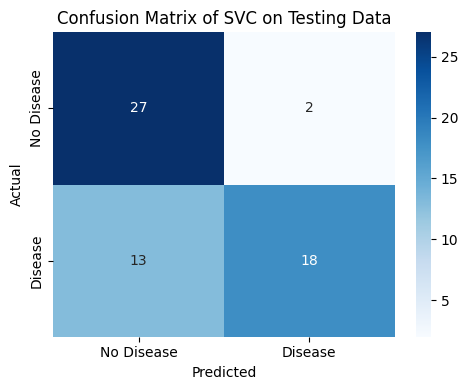

In [17]:
print("\nClassification Report:")
print("======================\n")
print(classification_report(
    model_predictions["HeartDisease"],
    model_predictions["Predictions"],
    target_names=["No Heart Disease (0)", "Heart Disease (1)"]
))

conf_matrix = confusion_matrix(model_predictions["HeartDisease"], model_predictions["Predictions"])

plt.figure(figsize=(5, 4))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues",
            xticklabels=["No Disease", "Disease"],
            yticklabels=["No Disease", "Disease"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix of SVC on Testing Data")
plt.tight_layout()
plt.show()

### Step 8: Execute the Application Phase

#### Step 8.1: Take Input from User

In [18]:
# Details of a new patient (change these values to test another patient)
chest_pain_input = "Asymptomatic"
exercise_angina_input = "Yes"
vessels_input = "Two"
thal_input = "Reversible"

print("ChestPain:", chest_pain_input)
print("ExerciseAngina:", exercise_angina_input)
print("Vessels:", vessels_input)
print("Thal:", thal_input)

ChestPain: Asymptomatic
ExerciseAngina: Yes
Vessels: Two
Thal: Reversible


#### Step 8.2: Convert User Input into Feature Vector (Exactly Same as Feature Vectors of Sample Data)

In [19]:
user_input = pd.DataFrame({
    "ChestPain": [chest_pain_input],
    "ExerciseAngina": [exercise_angina_input],
    "Vessels": [vessels_input],
    "Thal": [thal_input]
})

print("\n\nUser Input Feature Vector:")
print("==========================\n")
print(user_input)



User Input Feature Vector:

      ChestPain ExerciseAngina Vessels        Thal
0  Asymptomatic            Yes     Two  Reversible


#### Step 8.3: Label Encoding of Feature Vector (Exactly Same as Label Encoded Feature Vectors of Sample Data)

In [20]:
unseen_data_features = user_input.copy()

unseen_data_features["ChestPain"] = chest_pain_label_encoder.transform(user_input["ChestPain"])
unseen_data_features["ExerciseAngina"] = exercise_angina_label_encoder.transform(user_input["ExerciseAngina"])
unseen_data_features["Vessels"] = vessels_label_encoder.transform(user_input["Vessels"])
unseen_data_features["Thal"] = thal_label_encoder.transform(user_input["Thal"])

print("\n\nUser Input Encoded Feature Vector:")
print("==================================\n")
print(unseen_data_features)



User Input Encoded Feature Vector:

   ChestPain  ExerciseAngina  Vessels  Thal
0          0               1        2     2


#### Step 8.4: Load the Saved Model

In [21]:
with open("svc_trained_model.pkl", "rb") as file:
    model = pickle.load(file)

#### Step 8.5: Model Prediction

##### Step 8.5.1: Apply Model on the Label Encoded Feature Vector of unseen instance and return Prediction to the User

In [22]:
predicted_heart_disease = model.predict(unseen_data_features)

if predicted_heart_disease[0] == 1:
    prediction = "HEART DISEASE"
else:
    prediction = "NO HEART DISEASE"

pretty_table = PrettyTable()
pretty_table.add_column("       ** Prediction **       ", [prediction])

print(pretty_table)

+--------------------------------+
|        ** Prediction **        |
+--------------------------------+
|         HEART DISEASE          |
+--------------------------------+


### Step 9: Execute the Feedback Phase

#### Step 9.1: Collect Feedback from Users and Domain Experts on Performance of the Model Deployed in the Real World

In [23]:
# Feedback from testing the model
feedback = [
    "Patient with Asymptomatic chest pain, exercise angina Yes, Two vessels and Reversible thal was predicted HEART DISEASE. This matches the data.",
    "Patient with NonAnginal chest pain, exercise angina No, Zero vessels and Normal thal was predicted NO HEART DISEASE. This matches the data.",
    "The model missed 13 of the 31 heart disease patients in the testing data. This is risky for a medical system.",
    "No doctor has checked the predictions yet."
]

for number, item in enumerate(feedback, 1):
    print(number, item)

1 Patient with Asymptomatic chest pain, exercise angina Yes, Two vessels and Reversible thal was predicted HEART DISEASE. This matches the data.
2 Patient with NonAnginal chest pain, exercise angina No, Zero vessels and Normal thal was predicted NO HEART DISEASE. This matches the data.
3 The model missed 13 of the 31 heart disease patients in the testing data. This is risky for a medical system.
4 No doctor has checked the predictions yet.


#### Step 9.2: Make a List of Potential Improvements

In [24]:
improvements = [
    "Use more input attributes like age and gender",
    "Add the data of the other hospitals in the UCI dataset so there are more patients",
    "Try other models like Logistic Regression and Decision Tree and compare them with SVC",
    "Ask a doctor to check the predictions"
]

for number, item in enumerate(improvements, 1):
    print(number, item)

1 Use more input attributes like age and gender
2 Add the data of the other hospitals in the UCI dataset so there are more patients
3 Try other models like Logistic Regression and Decision Tree and compare them with SVC
4 Ask a doctor to check the predictions


#### Step 9.3: Improve the Model Based on Feedback

In [25]:
print("Next version: train the model again with more attributes and more patients, then test it again before replacing svc_trained_model.pkl")

Next version: train the model again with more attributes and more patients, then test it again before replacing svc_trained_model.pkl


### Step 10: Deploy the Model on the Cloud
- The trained model is deployed on Streamlit Community Cloud
- `app.py` loads `svc_trained_model.pkl`, takes the 4 inputs from the user and shows the prediction
- `requirements.txt` has the libraries needed by the app
- **Live App:** [https://heart-disease-fa24-bse-085.streamlit.app](https://heart-disease-fa24-bse-085.streamlit.app)
- **GitHub Repo:** [https://github.com/VicegerentPrince/ml-lab-assignment-2](https://github.com/VicegerentPrince/ml-lab-assignment-2)

## Conclusion
The Support Vector Classifier got an accuracy of 0.75 on the testing data (45 correct out of 60) using only 4 input attributes. It is good at finding patients without heart disease, but it missed 13 of the 31 patients with heart disease. More attributes and more data are needed to improve it. The trained model is deployed as a web app on Streamlit Community Cloud.